# Лабораторная работа 1. Сегментация потребителей леденцов

## Цель и постановка задачи

По ответам респондентов необходимо определить число кластеров, выбрать метод,
дающий ясное разделение, выполнить кластеризацию по мотивам потребления и содержательно объяснить группы.

## 1. Данные

Каждая строка представляет одного респондента, каждый столбец - оценку согласия
с высказыванием о цели потребления леденцов. Предполагаем, что большая оценка
означает более сильное согласие.

| Признак | Мотив потребления |
|---|---|
| V1 | Освежить дыхание |
| V2 | Чувствовать себя увереннее |
| V3 | Освежить полость рта |
| V4 | Избавиться от неприятного вкуса во рту |
| V5 | Заменить другие кондитерские изделия |
| V6 | Удовлетворить желание сладкого |
| V7 | Сконцентрироваться |
| V8 | Отвлечься на несколько минут и подумать |
| V9 | Облегчить боль в горле |
| V10 | Избавиться от заложенности носа |
| V11 | Улучшить самочувствие |

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score

df = pd.read_csv("Леденцы.dat", sep=";")

print(df.shape)
display(df.head())

(338, 11)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


В файле 338 респондентов и 11 числовых признаков, пропуски
отсутствуют. Наблюдаемые оценки лежат в диапазоне 2-5.
Совпадающие строки не удаляем, поскольку одинаковые ответы могли дать разные
люди. Удаление таких строк изменило бы веса наблюдений и доли сегментов.

## 2. Подготовка и выбор метода

Все признаки измерены одной шкалой, а выборочные стандартные отклонения близки
(примерно 0,82-0,99). Поэтому анализ выполняется на исходных оценках.

Используем агломеративную иерархическую кластеризацию методом Варда. Сначала каждый объект образует свой кластер, затем объединяется пара с минимальным приростом внутрикластерной суммы квадратов:

$$\Delta(A,B)=\frac{n_A n_B}{n_A+n_B}\|\bar{x}_A-\bar{x}_B\|^2.$$

Метод подходит для поиска компактных групп с различными средними профилями.
Число кластеров выбираем после построения дерева. В качестве метрики указываем `metric="euclidean"`. Ответы представляют собой векторы, потому евклидово расстояние видится разумным

## 3. Дендрограмма и предварительный выбор числа кластеров

На сокращённой дендрограмме показаны последние 30 ветвей. Числа в скобках
отражают количество наблюдений в свернутых ветвях.
Высота слияния характеризует неоднородность объединяемых групп по методу Варда.
Цветовой порог 20 расположен между слияниями на высотах около 13 и 30.

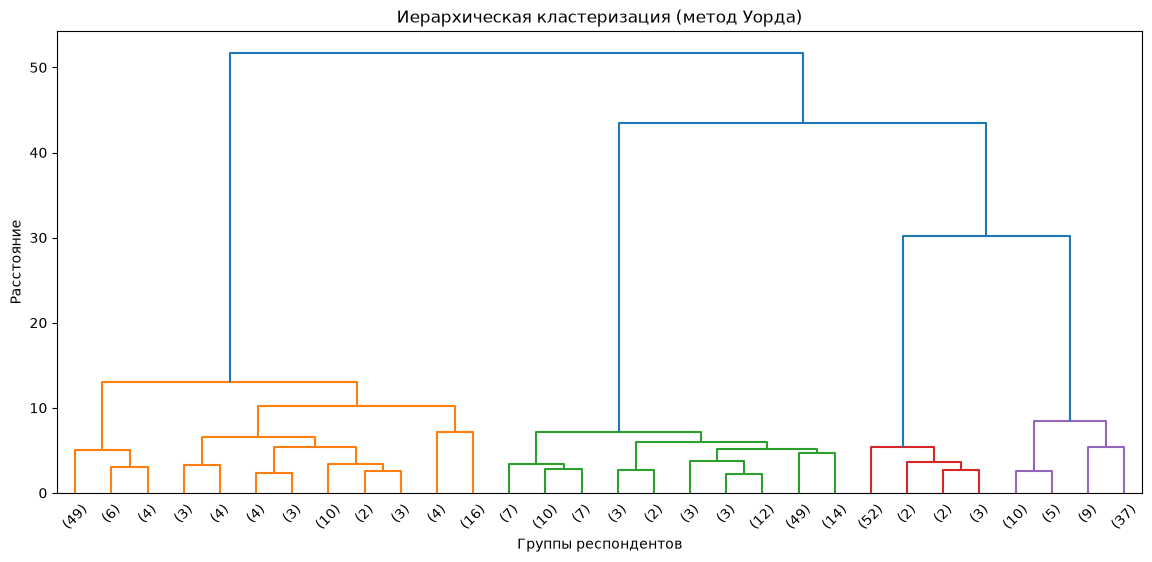

In [ ]:
Z = linkage(df, method="ward", metric="euclidean")

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    color_threshold=20
)

plt.title("Иерархическая кластеризация (метод Уорда)")
plt.xlabel("Группы респондентов")
plt.ylabel("Расстояние")

plt.show()

### Выбор числа кластеров

1. **Дендрограмма.** Ищем большой скачок высоты между последовательными слияниями.
   Чем выше происходит слияние, тем сильнее различаются объединяемые группы.
   Несложно заметить, что с опредлённого момента расстояние междду кластерами значительно увеличивается. Цветовой порог 20 на рисунке как раз соответствует такому разрезу.
   Однако следует проверить наш вывод более объективным критерием, в качестве которого выступит правило локтя
2. **Правило локтя.** Для каждого числа кластеров вычисляем WCSS - сумму квадратов
   расстояний от объектов до центров своих кластеров. При увеличении числа кластеров
   WCSS всегда уменьшается, поэтому ищем точку, после которой улучшение заметно
   замедляется. Значения для 2, 3, 4 и 5 кластеров составляют соответственно
   1823,30; 879,72; 423,14 и 338,25. После четырёх кластеров уменьшение становится
   существенно менее выраженным, то есть на графике формируется «локоть» около
   $k=4$.

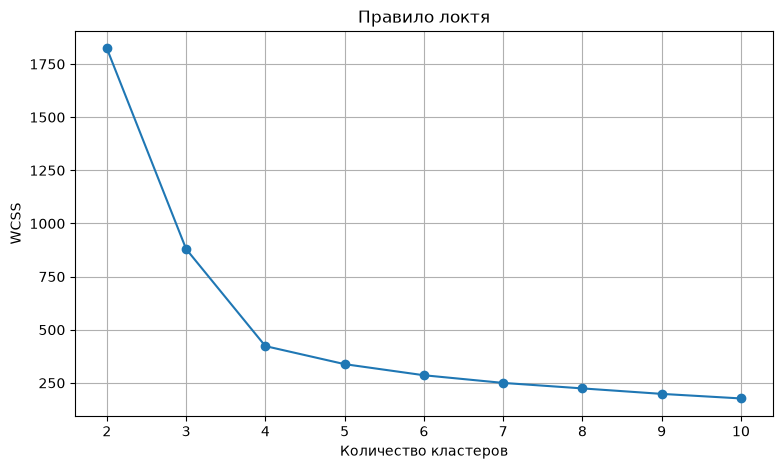

In [ ]:
from scipy.cluster.hierarchy import fcluster

X = df.drop(columns=["cluster"], errors="ignore").to_numpy()

k_values = range(2, 11)
wcss = []

for k in k_values:
    labels = fcluster(Z, t=k, criterion="maxclust")

    sse = 0
    for label in np.unique(labels):
        cluster = X[labels == label]
        center = cluster.mean(axis=0)
        sse += np.sum((cluster - center) ** 2)

    wcss.append(sse)

plt.figure(figsize=(9, 5))
plt.plot(k_values, wcss, marker="o")
plt.xlabel("Количество кластеров")
plt.ylabel("WCSS")
plt.title("Правило локтя")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### Дополнительная проверка коэффициентом силуэта

Коэффициент силуэта оценивает одновременно компактность кластеров и их отделённость
друг от друга. Для каждого объекта он определяется как

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))},$$

где $a(i)$ - среднее расстояние до объектов своего кластера, а $b(i)$ - наименьшее
среднее расстояние до объектов другого кластера. Значение близкое к 1 означает
хорошее соответствие объекта своему кластеру, около 0 - положение на границе,
отрицательное значение - возможное ошибочное отнесение.

Ниже сравнивается средний коэффициент силуэта для решений от 2 до 8 кластеров.
Этот критерий дополняет дендрограмму и правило локтя, но итоговый выбор также должен
учитывать размеры групп и возможность их содержательной интерпретации.

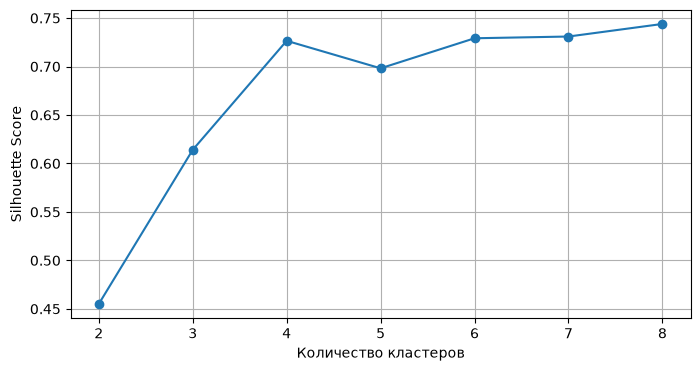

In [ ]:
scores = []

for k in range(2, 9):
    labels = fcluster(Z, t=k, criterion="maxclust")
    score = silhouette_score(df, labels)
    scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(range(2, 9), scores, marker="o")
plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

### Итоговый выбор числа кластеров
Как несложно заметить, значительные изменения по всем имеющимся критериям происходили именно при переходе к 4 группам, потому именно это значение и выберем как итоговое число кластеров.

Оно видится наиболее содержательным и устойчивым. Выборка при этом разбивается на группы, имеющих значительное число наблюдений и содержательную интерпретацию, что будет показано нинже

In [ ]:
df["cluster"] = fcluster(Z, t=4, criterion="maxclust")

print(df["cluster"].value_counts().sort_index())

cluster
1    108
2    110
3     59
4     61
Name: count, dtype: int64


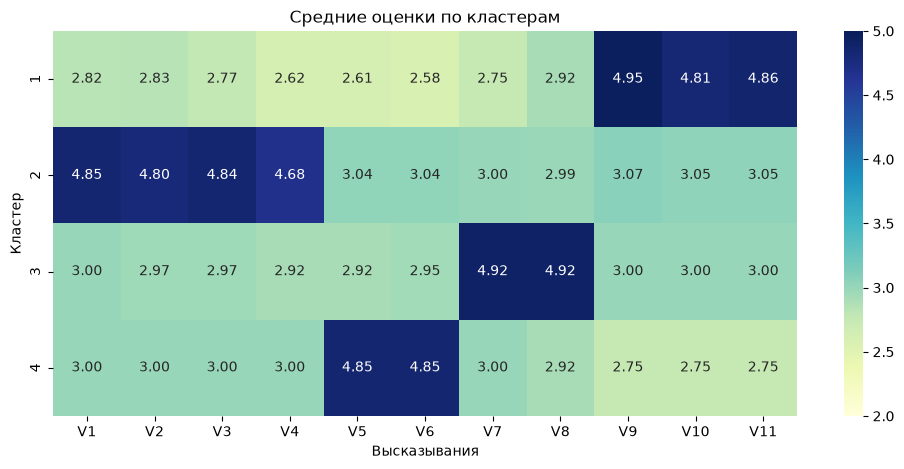

In [ ]:
import seaborn as sns

profile = df.groupby("cluster").mean()

plt.figure(figsize=(12, 5))

sns.heatmap(
    profile,
    annot=True,
    cmap="YlGnBu",
    vmin=2,
    vmax=5,
    fmt=".2f"
)

plt.title("Средние оценки по кластерам")
plt.xlabel("Высказывания")
plt.ylabel("Кластер")
plt.show()

### Содержательная интерпретация четырёх групп

| Кластер | Человек | Доля выборки | Условное название | Основание |
|---|---:|---:|---|---|
| 1 | 108 | 31,95% | Облегчение дискомфорта | V9=4,95; V10=4,81; V11=4,86 |
| 2 | 110 | 32,54% | Уверенность | V1=4,85; V2=4,80; V3=4,84; V4=4,68 |
| 3 | 59 | 17,46% | Концентрация | V7=4,92; V8=4,92 |
| 4 | 61 | 18,05% | Сладкоежки | V5=4,85; V6=4,85 |

**Кластер 1. Облегчение дискомфорта.** Леденцы прежде всего
ассоциируются с облегчением боли в горле, заложенности носа и улучшением
самочувствия. Остальные средние оценки преимущественно ниже 3

**Кластер 2. Уверенность.** Устранение неприятного вкуса во рту, свежесть дыхания и прочие мотивы, связанные с психическим дискомфортом. Остальные мотивы имеют
средние оценки около 3. В выборке это самый большой сегмент.

**Кластер 3. Концентрация.** Высокие оценки V7-V8 показывают
связь потребления с сосредоточением и возможностью ненадолго отвлечься и подумать.
Другие мотивы выражены слабее. Утверждать по этим данным, что участники являются
студентами или офисными работниками, нельзя: таких признаков нет.

**Кластер 4. Сладкоежки** Леденцы рассматриваются как сладость и
альтернатива другим кондитерским изделиям.

Названия описывают различия средних профилей, а не каждого участника без исключения.
Все четыре сегмента достаточно заметны в данной выборке: минимальный содержит
59 человек, или 17,46%. Это не оценка долей всего рынка.